# R-MOVE · M2 · Experimentos para optimizar el método de clustering

Notebook de pruebas: el notebook limpio de M2 no se modifica. Aquí se comparan variantes del método de clustering con una métrica fijada de antemano. La variante ganadora se trasladará después al notebook de M2.

**Regla de decisión (fijada antes de mirar los resultados):** cada variante se evalúa con *días limpios usados como falsos días de caos* (validación leave-one-out). Como esos días no tuvieron ninguna incidencia, el efecto real es 0, y lo que estima el método es error. Gana la variante con **menor RMSE** en los municipios dependientes, siempre que el **sesgo** sea ≈ 0. Los días de caos reales **no** se usan para elegir el método.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "data" / "processed" / "rmove"

cal  = pd.read_parquet(OUT / "m2_cal.parquet")
info = pd.read_parquet(OUT / "m2_info_municipios.parquet")
V    = pd.read_parquet(OUT / "m2_panel_V.parquet")
ctrl_codes = pd.read_parquet(OUT / "m2_ctrl_codes.parquet").municipio_code.tolist()
caos_real  = pd.DatetimeIndex(pd.to_datetime(pd.read_parquet(OUT / "m2_caos_real.parquet").fecha))
cal.index, V.index = pd.to_datetime(cal.index), pd.to_datetime(V.index)

print("Panel V:", V.shape, "| días de caos:", [f"{d:%d/%m/%Y}" for d in caos_real])

Panel V: (266, 133) | días de caos: ['13/05/2024', '17/03/2025', '26/03/2025', '01/04/2025']


In [2]:
CTRL_G = "Sin Rodalies (control)"
GRUPOS = {
    "Dependientes":           info.index[info.dependiente],
    "Cercanos sin metro/FGC": info.index[info.rodalies & ~info.dependiente & ~info.con_alt],
    "Con metro/FGC":          info.index[info.con_alt],
    CTRL_G:                   pd.Index(ctrl_codes),
}
GRUPOS = {g: [c for c in codes if c in V.columns] for g, codes in GRUPOS.items()}
EVAL = [g for g in GRUPOS if g != CTRL_G]          # el control no se evalúa contra sí mismo

S    = pd.DataFrame({g: V[c].sum(axis=1, min_count=1) for g, c in GRUPOS.items()})
logC = np.log(V[GRUPOS[CTRL_G]].sum(axis=1, min_count=len(GRUPOS[CTRL_G]) // 2))   # = vol_ctrl de M2

LIMPIOS = cal.index[cal.limpio].intersection(logC.dropna().index).intersection(S.dropna().index)
print({g: len(c) for g, c in GRUPOS.items()})       # esperado ≈ 35 / 16 / 11 / 71
print(pd.Series(LIMPIOS.year).value_counts().sort_index().rename("días limpios"))

{'Dependientes': 35, 'Cercanos sin metro/FGC': 16, 'Con metro/FGC': 11, 'Sin Rodalies (control)': 71}
2023    118
2024     87
2025     56
Name: días limpios, dtype: int64


## Piezas del método

Cada variante combina dos piezas:
1. **Selector de días de referencia:** a partir de los días limpios del mismo año, decide con qué días se compara el día analizado. El método actual usa un K-means (k = 3) sobre el log del volumen total del control y se queda con los días del mismo tipo.
2. **Estimador del efecto** (en log; % = (e^x − 1) × 100):
   - **M0 · Actual:** log(viajes del grupo / mediana del grupo en los días de referencia).
   - **M1 · Ratio de ratios:** M0 del grupo − M0 del control. Resta el choque común del día, como un DiD dentro del cluster.
   - **M1b · Ratio de ratios por municipio:** el ratio se calcula municipio a municipio, se agrega ponderando por el volumen normal de cada municipio y se le resta el control. Así un municipio grande no domina el resultado.

In [3]:
def ref_kmeans_1d(train, d, k=3, seed=0):
    """Días de referencia = días limpios del mismo tipo (K-means 1D sobre el log del volumen del control)."""
    km = KMeans(k, n_init=20, random_state=seed).fit(logC.loc[train].to_frame("x"))
    tipo = km.predict(pd.DataFrame({"x": [logC.loc[d]]}))[0]
    return train[km.labels_ == tipo]

def ef_m0(d, ref, g):
    return np.log(S.at[d, g] / S.loc[ref, g].median())

def ef_m1(d, ref, g):
    return ef_m0(d, ref, g) - ef_m0(d, ref, CTRL_G)

def ef_m1b(d, ref, g):
    codes = GRUPOS[g]
    base = V.loc[ref, codes].median()
    r = np.log(V.loc[d, codes] / base)
    ok = r.notna() & base.notna() & np.isfinite(r)
    return np.average(r[ok], weights=base[ok]) - ef_m0(d, ref, CTRL_G)

ESTIMADORES = {"M0 actual": ef_m0, "M1 ratio de ratios": ef_m1, "M1b ratio por municipio": ef_m1b}
pct = lambda x: (np.exp(x) - 1) * 100

In [4]:
# Selector entrenado con todos los días limpios del año, como en M2. Esperado para Dependientes con M0:
# 13/05/2024 ≈ −8,1 %, 17/03/2025 ≈ −9,7 %. Si no coincide, hay algún problema en la carga de los datos.
ver = []
for d in caos_real:
    ref = ref_kmeans_1d(LIMPIOS[LIMPIOS.year == d.year], d)
    ver.append({"fecha": f"{d:%d/%m/%Y}", "días ref": len(ref),
                **{g: round(pct(ef_m0(d, ref, g)), 1) for g in EVAL}})
pd.DataFrame(ver).set_index("fecha")

,días ref,Dependientes,Cercanos sin metro/FGC,Con metro/FGC
fecha,,,,
13/05/2024,31,-8.9,-1.9,2.7
17/03/2025,23,-9.9,-2.5,-2.9
26/03/2025,23,3.4,-3.8,-4.4
01/04/2025,23,-6.2,-5.1,-4.9


## Fase 0 · Banco de pruebas: días limpios como placebo

Para cada día limpio *d* de cada año: se aparta *d*, se reentrena el selector con el resto de días limpios del año y se estima el efecto en *d* con cada estimador. Como el efecto real es 0:
- **Sesgo** = media del efecto estimado (debería ser ≈ 0).
- **RMSE** = error típico del método (métrica principal).
- **P2,5–P97,5** = intervalo de los placebos: un efecto real fuera de este rango es detectable.

In [6]:
def backtest(selector, estimadores, **kw):
    filas = []
    for y in sorted(LIMPIOS.year.unique()):
        dias_y = LIMPIOS[LIMPIOS.year == y]
        for d in dias_y:
            ref = selector(dias_y.drop(d), d, **kw)
            for m, f in estimadores.items():
                for g in EVAL:
                    filas.append((d, m, g, f(d, ref, g)))
    return pd.DataFrame(filas, columns=["fecha", "metodo", "grupo", "log_ef"])

def metricas(bt):
    return bt.groupby(["grupo", "metodo"]).log_ef.agg(
        sesgo_pct=lambda x: pct(x.mean()),
        rmse_pct=lambda x: np.sqrt((x ** 2).mean()) * 100,
        p2_5=lambda x: pct(x.quantile(.025)),
        p97_5=lambda x: pct(x.quantile(.975)),
        n="size").round(2)

bt_f1 = backtest(ref_kmeans_1d, ESTIMADORES)
RESULTADOS = {"F1 · K-means 1D, k=3": bt_f1}          # aquí iremos acumulando las variantes
metricas(bt_f1)

sesgo_pct  rmse_pct  p2_5  \
grupo                  metodo                                               
Cercanos sin metro/FGC M0 actual                    -0.16      3.03 -5.56   
                       M1 ratio de ratios           -0.16      2.48 -4.59   
                       M1b ratio por municipio       0.10      2.40 -4.03   
Con metro/FGC          M0 actual                    -0.04      2.59 -4.66   
                       M1 ratio de ratios           -0.04      1.93 -3.38   
                       M1b ratio por municipio       0.21      1.91 -3.01   
Dependientes           M0 actual                    -0.21      3.61 -6.79   
                       M1 ratio de ratios           -0.22      3.45 -7.30   
                       M1b ratio por municipio      -0.29      3.47 -7.48   

                                                p97_5    n  
grupo                  metodo                               
Cercanos sin metro/FGC M0 actual                 5.52  261  
                       M1 ratio de ratios        4.95  261  
                       M1b ratio por municipio   5.18  261  
Con metro/FGC          M0 actual                 5.20  261  
                       M1 ratio de ratios        4.03  261  
                       M1b ratio por municipio   4.11  261  
Dependientes           M0 actual                 6.49  261  
                       M1 ratio de ratios        5.77  261  
                       M1b ratio por municipio   6.00  261

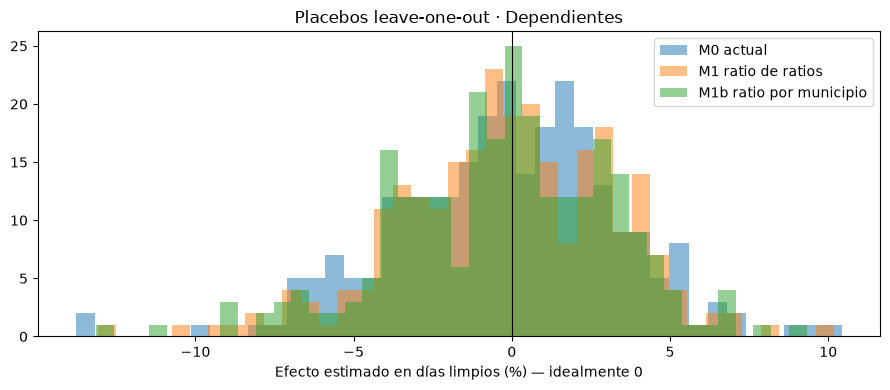

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
sub = bt_f1[bt_f1.grupo == "Dependientes"]
for m in ESTIMADORES:
    ax.hist(pct(sub[sub.metodo == m].log_ef), bins=40, alpha=.5, label=m)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Efecto estimado en días limpios (%) — idealmente 0")
ax.set_title("Placebos leave-one-out · Dependientes"); ax.legend(); plt.tight_layout(); plt.show()

## Resultado de la Fase 1
El ratio de ratios (M1) reduce el error en todos los grupos sin introducir sesgo, sobre todo en los grupos cercanos a Barcelona. En los dependientes la mejora es pequeña (RMSE de 3,6 % a 3,5 %). **A partir de aquí se usa M1.** M1b no mejora a M1 y es más complejo.

## Diagnóstico: ¿qué explica el error de los dependientes?
M1 supone que, en los días del mismo tipo, el cociente dependientes/control es constante. Se mide qué parte de la variación de ese cociente en los días limpios se explica por el año, el mes y el día de la semana.

C:\Users\marti\AppData\Local\Temp\ipykernel_17388\4111624269.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  D = pd.DataFrame({"r": r, "año": LIMPIOS.year, "mes": LIMPIOS.month, "dow": LIMPIOS.dayofweek}, index=LIMPIOS)


Var. explicada por el año:                36%
Dentro del año, por el mes:               24%
Dentro del año, por el día de la semana:  3%
Dentro del año, por el volumen del control (corr.): -0.40


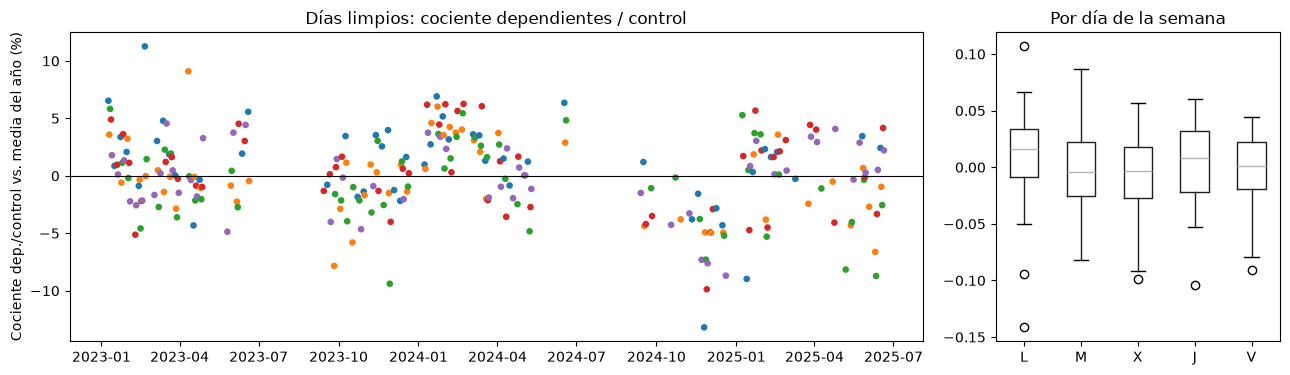

In [8]:
r = np.log(S.loc[LIMPIOS, "Dependientes"] / S.loc[LIMPIOS, CTRL_G]).rename("r")
D = pd.DataFrame({"r": r, "año": LIMPIOS.year, "mes": LIMPIOS.month, "dow": LIMPIOS.dayofweek}, index=LIMPIOS)
D["r_año"] = D.r - D.groupby("año").r.transform("mean")          # sin el efecto del año

def r2(col, factor):
    return 1 - D.groupby(factor)[col].transform(lambda x: x - x.mean()).var() / D[col].var()

print(f"Var. explicada por el año:                {r2('r', 'año'):.0%}")
print(f"Dentro del año, por el mes:               {r2('r_año', 'mes'):.0%}")
print(f"Dentro del año, por el día de la semana:  {r2('r_año', 'dow'):.0%}")
print(f"Dentro del año, por el volumen del control (corr.): {np.corrcoef(D.r_año, logC.loc[LIMPIOS])[0,1]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
sc = ax[0].scatter(D.index, pct(D.r_año), c=D.dow, cmap="tab10", vmin=0, vmax=9, s=14)
ax[0].axhline(0, color="black", lw=.8); ax[0].set_ylabel("Cociente dep./control vs. media del año (%)")
ax[0].set_title("Días limpios: cociente dependientes / control")
D.boxplot(column="r_año", by="dow", ax=ax[1], grid=False)
ax[1].set_xticklabels(["L", "M", "X", "J", "V"]); ax[1].set_title("Por día de la semana"); ax[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

## Fase 2 · ¿Con qué variables se agrupan los días?
Todas las variantes usan el estimador M1 y k = 3. Solo cambia el selector de días de referencia:
- **S1 · Volumen total** (actual): log del volumen total del control.
- **S2 · Perfil del control:** log(viajes) de cada municipio de control, estandarizado y reducido a 3 componentes principales (PCA). Recoge la *forma* del día, no solo cuánto se viaja.
- **S3 · Volumen + día de la semana.**
- **S4 · Volumen + posición en el año:** permite que el cociente evolucione a lo largo del año.
- **S5 · Volumen + día de la semana + posición en el año.**
- **T20 · Comparador sin clusters:** los 20 días limpios más cercanos en el tiempo.

El escalado, el PCA y el K-means se ajustan solo con los días de entrenamiento de cada iteración, sin usar el día analizado.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def ref_kmeans(train, d, X, k=3, n_pca=None, seed=0):
    """Días de referencia = días de entrenamiento del mismo cluster que d (K-means sobre las variables X)."""
    sc = StandardScaler().fit(X.loc[train])
    Xt, Xd = sc.transform(X.loc[train]), sc.transform(X.loc[[d]])
    if n_pca:
        p = PCA(n_pca, random_state=seed).fit(Xt)
        Xt, Xd = p.transform(Xt), p.transform(Xd)
    km = KMeans(k, n_init=20, random_state=seed).fit(Xt)
    return train[km.labels_ == km.predict(Xd)[0]]

def ref_tiempo(train, d, n=20):
    """Comparador sin clusters: los n días limpios más cercanos en el tiempo."""
    dist = np.abs((train - d).days)
    return train[np.argsort(dist)[:n]]

# Variables por día (para todos los días: limpios + caos)
dias = V.index
logV_ctrl = np.log(V[GRUPOS[CTRL_G]])
logV_ctrl = logV_ctrl.fillna(logV_ctrl.median())                       # huecos puntuales → mediana del municipio
dow = pd.get_dummies(dias.dayofweek, prefix="dow").set_index(dias).astype(float)
pos = pd.DataFrame({"t": dias.dayofyear / 365}, index=dias)

X = {"S1 volumen":            logC.to_frame("logC"),
     "S2 perfil (PCA 3)":     logV_ctrl,
     "S3 volumen + dow":      pd.concat([logC.rename("logC"), dow], axis=1),
     "S4 volumen + año":      pd.concat([logC.rename("logC"), pos], axis=1),
     "S5 volumen + dow + año": pd.concat([logC.rename("logC"), dow, pos], axis=1)}

C:\Users\marti\AppData\Local\Temp\ipykernel_17388\1503153600.py:23: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = pd.get_dummies(dias.dayofweek, prefix="dow").set_index(dias).astype(float)
C:\Users\marti\AppData\Local\Temp\ipykernel_17388\1503153600.py:24: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  pos = pd.DataFrame({"t": dias.dayofyear / 365}, index=dias)


In [10]:
M1 = {"M1": ef_m1}
for nombre, Xs in X.items():
    print("→", nombre)
    RESULTADOS[f"F2 · {nombre}"] = backtest(ref_kmeans, M1, X=Xs, n_pca=3 if "PCA" in nombre else None)
RESULTADOS["F2 · T20 tiempo"] = backtest(ref_tiempo, M1)

def tabla_resultados(grupo="Dependientes"):
    filas = {}
    for nombre, bt in RESULTADOS.items():
        sub = bt[(bt.grupo == grupo) & (bt.metodo.str.startswith("M1"))]
        sub = sub[sub.metodo == sub.metodo.iloc[0]]                    # en F1 hay M1 y M1b: se toma M1
        x = sub.log_ef
        filas[nombre] = {"sesgo_pct": pct(x.mean()), "rmse_pct": np.sqrt((x**2).mean()) * 100,
                         "p2_5": pct(x.quantile(.025)), "p97_5": pct(x.quantile(.975))}
    return pd.DataFrame(filas).T.round(2).sort_values("rmse_pct")

display(tabla_resultados("Dependientes"))
display(tabla_resultados("Cercanos sin metro/FGC"))

→ S1 volumen
→ S2 perfil (PCA 3)
→ S3 volumen + dow
→ S4 volumen + año
→ S5 volumen + dow + año


,sesgo_pct,rmse_pct,p2_5,p97_5
F2 · S2 perfil (PCA 3),0.22,3.05,-5.86,5.65
F2 · S4 volumen + año,0.08,3.07,-6.00,5.17
F2 · T20 tiempo,0.31,3.12,-6.25,5.72
"F1 · K-means 1D, k=3",-0.22,3.45,-7.30,5.77
F2 · S1 volumen,-0.22,3.45,-7.30,5.77
F2 · S3 volumen + dow,0.25,3.65,-7.28,6.48
F2 · S5 volumen + dow + año,0.38,3.66,-7.11,6.72


,sesgo_pct,rmse_pct,p2_5,p97_5
F2 · T20 tiempo,-0.20,2.25,-4.16,4.53
F2 · S4 volumen + año,0.08,2.36,-3.87,4.96
F2 · S5 volumen + dow + año,0.36,2.37,-3.85,5.44
F2 · S3 volumen + dow,0.34,2.39,-3.99,5.48
F2 · S2 perfil (PCA 3),0.04,2.44,-4.14,5.37
F2 · S1 volumen,-0.16,2.48,-4.59,4.95
"F1 · K-means 1D, k=3",-0.16,2.48,-4.59,4.95


## Resultado de la Prueba 2
- El cociente dependientes/control tiene **estacionalidad**: es alto de enero a marzo y bajo de octubre a diciembre (dentro del año, el mes explica el 24 % de la variación). El día de la semana casi no influye (3 %).
- Las variantes que eligen días de la **misma época del año** reducen el error típico de los dependientes de un 3,45 % a ≈ 3,05–3,12 %: el perfil del control, el volumen + la época del año y los 20 días más cercanos en el tiempo. Añadir el día de la semana empeora el resultado.

## Prueba 3 · Número de tipos de día y combinación de variables
Para los mejores candidatos se prueba k = 2…6 y una variante nueva: **perfil del control + época del año**. Con el comparador sin clusters se prueba el número de días cercanos. Para dar a la época del año un peso comparable al resto de variables, se escala a la misma desviación típica que la primera variable.

In [11]:
def ref_kmeans2(train, d, X, k=3, n_pca=None, extra=None, peso=1.0, seed=0):
    """K-means sobre X (opcionalmente reducido con PCA) + variables extra (p. ej., época del año) con el mismo peso."""
    sc = StandardScaler().fit(X.loc[train])
    Xt, Xd = sc.transform(X.loc[train]), sc.transform(X.loc[[d]])
    if n_pca:
        p = PCA(n_pca, random_state=seed).fit(Xt)
        Xt, Xd = p.transform(Xt), p.transform(Xd)
    if extra is not None:
        se = StandardScaler().fit(extra.loc[train])
        f = peso * Xt[:, 0].std()
        Xt = np.hstack([Xt, se.transform(extra.loc[train]) * f])
        Xd = np.hstack([Xd, se.transform(extra.loc[[d]]) * f])
    km = KMeans(k, n_init=10, random_state=seed).fit(Xt)
    return train[km.labels_ == km.predict(Xd)[0]]

In [12]:
CANDIDATOS = {
    "S2 perfil":          dict(X=logV_ctrl, n_pca=3),
    "S4 volumen + época": dict(X=logC.to_frame("logC"), extra=pos),
    "S6 perfil + época":  dict(X=logV_ctrl, n_pca=3, extra=pos),
}
for nombre, cfg in CANDIDATOS.items():
    for k in [2, 3, 4, 5, 6]:
        print("→", nombre, "k =", k)
        RESULTADOS[f"F3 · {nombre}, k={k}"] = backtest(ref_kmeans2, M1, k=k, **cfg)
for n in [10, 15, 30, 40]:
    RESULTADOS[f"F3 · T{n} tiempo"] = backtest(ref_tiempo, M1, n=n)

display(tabla_resultados("Dependientes").head(12))
display(tabla_resultados("Cercanos sin metro/FGC").head(12))

→ S2 perfil k = 2
→ S2 perfil k = 3
→ S2 perfil k = 4
→ S2 perfil k = 5
→ S2 perfil k = 6
→ S4 volumen + época k = 2
→ S4 volumen + época k = 3
→ S4 volumen + época k = 4
→ S4 volumen + época k = 5
→ S4 volumen + época k = 6
→ S6 perfil + época k = 2
→ S6 perfil + época k = 3
→ S6 perfil + época k = 4
→ S6 perfil + época k = 5
→ S6 perfil + época k = 6


,sesgo_pct,rmse_pct,p2_5,p97_5
"F3 · S4 volumen + época, k=4",0.11,3.01,-6.12,5.25
"F3 · S2 perfil, k=4",0.16,3.04,-5.84,5.97
"F3 · S4 volumen + época, k=5",0.03,3.04,-6.19,5.08
F2 · S2 perfil (PCA 3),0.22,3.05,-5.86,5.65
"F3 · S2 perfil, k=3",0.22,3.05,-5.86,5.65
F2 · S4 volumen + año,0.08,3.07,-6.00,5.17
"F3 · S6 perfil + época, k=3",0.12,3.07,-6.20,5.61
"F3 · S4 volumen + época, k=3",0.07,3.08,-6.00,5.17
"F3 · S4 volumen + época, k=6",-0.08,3.08,-6.78,5.26
"F3 · S6 perfil + época, k=4",0.11,3.09,-6.26,5.67


,sesgo_pct,rmse_pct,p2_5,p97_5
F2 · T20 tiempo,-0.20,2.25,-4.16,4.53
F3 · T30 tiempo,-0.15,2.27,-3.98,5.18
F3 · T15 tiempo,-0.03,2.29,-3.96,4.62
F3 · T10 tiempo,-0.03,2.30,-4.03,5.26
F3 · T40 tiempo,0.03,2.34,-4.11,5.60
F2 · S4 volumen + año,0.08,2.36,-3.87,4.96
"F3 · S4 volumen + época, k=3",0.08,2.36,-3.87,4.96
F2 · S5 volumen + dow + año,0.36,2.37,-3.85,5.44
F2 · S3 volumen + dow,0.34,2.39,-3.99,5.48
"F3 · S6 perfil + época, k=4",0.04,2.40,-4.28,5.10


### ¿Las mejoras son reales o ruido?
Bootstrap por bloques mensuales: se remuestrean meses completos (no días sueltos, porque los días seguidos se parecen entre sí) y se recalcula la diferencia de error típico entre cada variante y el método actual. Si el intervalo del 95 % de la mejora no incluye el 0, la mejora es real.

In [13]:
BASE = "F1 · K-means 1D, k=3"

def efectos(nombre, grupo):
    bt = RESULTADOS[nombre]
    return bt[(bt.grupo == grupo) & bt.metodo.isin(["M1", "M1 ratio de ratios"])].set_index("fecha").log_ef

def comparar_pareado(a, b, grupo="Dependientes", n=2000, seed=0):
    """Mejora del error típico de b respecto a a (puntos %), con bootstrap por meses."""
    xa, xb = efectos(a, grupo).align(efectos(b, grupo), join="inner")
    mes = xa.index.to_period("M")
    bloques = [np.where(mes == m)[0] for m in mes.unique()]
    rng = np.random.default_rng(seed)
    rmse = lambda x: np.sqrt((x ** 2).mean()) * 100
    difs = []
    for _ in range(n):
        idx = np.concatenate([bloques[i] for i in rng.integers(0, len(bloques), len(bloques))])
        difs.append(rmse(xa.values[idx]) - rmse(xb.values[idx]))
    difs = np.array(difs)
    return {"mejora (pp)": round(rmse(xa) - rmse(xb), 2),
            "IC95 mejora": f"[{np.quantile(difs, .025):.2f}, {np.quantile(difs, .975):.2f}]",
            "P(mejor)": round((difs > 0).mean(), 3)}

for g in ["Dependientes", "Cercanos sin metro/FGC"]:
    top = tabla_resultados(g).index[:6]
    print(f"\n{g}: mejora respecto al método actual")
    display(pd.DataFrame({v: comparar_pareado(BASE, v, g) for v in top}).T)
    print(f"{g}: diferencia respecto a la mejor variante ({top[0]})")
    display(pd.DataFrame({v: comparar_pareado(v, top[0], g) for v in top[1:]}).T)


Dependientes: mejora respecto al método actual


,mejora (pp),IC95 mejora,P(mejor)
"F3 · S4 volumen + época, k=4",0.44,"[0.04, 0.90]",0.99
"F3 · S2 perfil, k=4",0.42,"[0.03, 0.86]",0.984
"F3 · S4 volumen + época, k=5",0.41,"[0.01, 0.88]",0.978
F2 · S2 perfil (PCA 3),0.41,"[0.02, 0.83]",0.982
"F3 · S2 perfil, k=3",0.41,"[0.02, 0.83]",0.982
F2 · S4 volumen + año,0.38,"[-0.03, 0.84]",0.958


Dependientes: diferencia respecto a la mejor variante (F3 · S4 volumen + época, k=4)


,mejora (pp),IC95 mejora,P(mejor)
"F3 · S2 perfil, k=4",0.02,"[-0.15, 0.17]",0.618
"F3 · S4 volumen + época, k=5",0.03,"[-0.06, 0.12]",0.772
F2 · S2 perfil (PCA 3),0.03,"[-0.13, 0.19]",0.642
"F3 · S2 perfil, k=3",0.03,"[-0.13, 0.19]",0.644
F2 · S4 volumen + año,0.06,"[-0.06, 0.18]",0.838



Cercanos sin metro/FGC: mejora respecto al método actual


,mejora (pp),IC95 mejora,P(mejor)
F2 · T20 tiempo,0.23,"[0.04, 0.44]",0.994
F3 · T30 tiempo,0.21,"[0.03, 0.41]",0.992
F3 · T15 tiempo,0.19,"[-0.10, 0.47]",0.904
F3 · T10 tiempo,0.18,"[-0.02, 0.38]",0.962
F3 · T40 tiempo,0.14,"[0.02, 0.27]",0.988
F2 · S4 volumen + año,0.12,"[0.01, 0.23]",0.982


Cercanos sin metro/FGC: diferencia respecto a la mejor variante (F2 · T20 tiempo)


,mejora (pp),IC95 mejora,P(mejor)
F3 · T30 tiempo,0.01,"[-0.07, 0.09]",0.608
F3 · T15 tiempo,0.04,"[-0.10, 0.20]",0.621
F3 · T10 tiempo,0.05,"[-0.03, 0.13]",0.867
F3 · T40 tiempo,0.08,"[-0.05, 0.24]",0.879
F2 · S4 volumen + año,0.11,"[-0.08, 0.31]",0.866


## Resultado de la Prueba 3
- Las mejores variantes reducen el error típico de los dependientes de un 3,45 % a ≈ 3,0 %, y la mejora es significativa con el bootstrap por meses (IC del 95 % sin el 0).
- Entre las mejores variantes, las diferencias no son significativas. Se elige la más simple e interpretable: **K-means sobre el volumen del control + la época del año, k = 4**. En los municipios cercanos su error no es significativamente peor que el de la mejor variante.

## Prueba 4 · Algoritmo y peso de la época del año
Con las mismas variables (volumen + época del año) se prueban un GMM y un clustering jerárquico de Ward, y K-means dando la mitad o el doble de peso a la época del año.

In [14]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering

def matriz(train, d, X, extra=None, peso=1.0):
    sc = StandardScaler().fit(X.loc[train])
    Xt, Xd = sc.transform(X.loc[train]), sc.transform(X.loc[[d]])
    if extra is not None:
        se, f = StandardScaler().fit(extra.loc[train]), peso * Xt[:, 0].std()
        Xt = np.hstack([Xt, se.transform(extra.loc[train]) * f])
        Xd = np.hstack([Xd, se.transform(extra.loc[[d]]) * f])
    return Xt, Xd

def ref_gmm(train, d, X, k=4, extra=None, peso=1.0, seed=0):
    Xt, Xd = matriz(train, d, X, extra, peso)
    gm = GaussianMixture(k, n_init=5, random_state=seed).fit(Xt)
    return train[gm.predict(Xt) == gm.predict(Xd)[0]]

def ref_ward(train, d, X, k=4, extra=None, peso=1.0):
    Xt, Xd = matriz(train, d, X, extra, peso)
    lab = AgglomerativeClustering(k, linkage="ward").fit_predict(Xt)
    cent = np.array([Xt[lab == c].mean(axis=0) for c in range(k)])
    return train[lab == np.argmin(((cent - Xd) ** 2).sum(axis=1))]

S4 = dict(X=logC.to_frame("logC"), extra=pos)
for p in [0.5, 2.0]:
    RESULTADOS[f"F4 · S4 K-means, k=4, peso época {p}"] = backtest(ref_kmeans2, M1, k=4, peso=p, **S4)
for k in [3, 4]:
    RESULTADOS[f"F4 · S4 GMM, k={k}"]  = backtest(ref_gmm,  M1, k=k, **S4)
    RESULTADOS[f"F4 · S4 Ward, k={k}"] = backtest(ref_ward, M1, k=k, **S4)

ELEGIDA = "F3 · S4 volumen + época, k=4"
for g in ["Dependientes", "Cercanos sin metro/FGC"]:
    nuevas = [v for v in RESULTADOS if v.startswith("F4")]
    print(f"\n{g}: Prueba 4 respecto a la variante elegida")
    display(pd.DataFrame({v: {"rmse_pct": round(np.sqrt((efectos(v, g) ** 2).mean()) * 100, 2),
                              **comparar_pareado(ELEGIDA, v, g)} for v in nuevas}).T)


Dependientes: Prueba 4 respecto a la variante elegida


,rmse_pct,mejora (pp),IC95 mejora,P(mejor)
"F4 · S4 K-means, k=4, peso época 0.5",3.2,-0.18,"[-0.38, -0.01]",0.02
"F4 · S4 K-means, k=4, peso época 2.0",3.08,-0.06,"[-0.21, 0.07]",0.18
"F4 · S4 GMM, k=3",3.16,-0.15,"[-0.26, -0.06]",0.0
"F4 · S4 Ward, k=3",3.06,-0.04,"[-0.17, 0.09]",0.254
"F4 · S4 GMM, k=4",3.17,-0.16,"[-0.27, -0.06]",0.001
"F4 · S4 Ward, k=4",3.06,-0.05,"[-0.14, 0.04]",0.11



Cercanos sin metro/FGC: Prueba 4 respecto a la variante elegida


,rmse_pct,mejora (pp),IC95 mejora,P(mejor)
"F4 · S4 K-means, k=4, peso época 0.5",2.45,0.02,"[-0.08, 0.11]",0.688
"F4 · S4 K-means, k=4, peso época 2.0",2.46,0.02,"[-0.09, 0.14]",0.658
"F4 · S4 GMM, k=3",2.43,0.05,"[-0.09, 0.19]",0.724
"F4 · S4 Ward, k=3",2.42,0.06,"[-0.09, 0.20]",0.776
"F4 · S4 GMM, k=4",2.37,0.11,"[-0.01, 0.24]",0.958
"F4 · S4 Ward, k=4",2.45,0.03,"[-0.08, 0.13]",0.691


### Estabilidad e interpretación de los tipos de día
Un tipo de día solo tiene sentido si no cambia al remuestrear los datos. Para cada año se repite el clustering 200 veces con remuestreo bootstrap de los días limpios, y se compara con el clustering original mediante el índice de Rand ajustado (ARI: 1 = idéntico, > 0,75 = estable). A continuación se describe cada tipo de día.

In [15]:

from sklearn.metrics import adjusted_rand_score

def clusters_s4(dias, k=4, seed=0):
    Xt, _ = matriz(dias, dias[0], **S4)
    return KMeans(k, n_init=10, random_state=seed).fit(Xt).labels_

estab, desc = {}, []
for y in sorted(LIMPIOS.year.unique()):
    dias_y = LIMPIOS[LIMPIOS.year == y]
    lab = pd.Series(clusters_s4(dias_y), index=dias_y)
    rng, aris = np.random.default_rng(0), []
    for i in range(200):
        bs = dias_y[np.unique(rng.integers(0, len(dias_y), len(dias_y)))]
        aris.append(adjusted_rand_score(lab.loc[bs], clusters_s4(bs, seed=i)))
    estab[y] = {"ARI medio": round(np.mean(aris), 2), "ARI P5": round(np.quantile(aris, .05), 2)}
    for c, dd in lab.groupby(lab).groups.items():
        dd = pd.DatetimeIndex(dd)
        desc.append({"año": y, "tipo": c, "días": len(dd),
                     "de": f"{dd.min():%d/%m}", "a": f"{dd.max():%d/%m}",
                     "meses": ", ".join(sorted(set(dd.strftime("%b")), key=lambda m: pd.to_datetime(m, format="%b").month)),
                     "viajes control (media)": round(np.exp(logC.loc[dd]).mean()),
                     "cociente dep./ctrl (%)": round(pct(r.loc[dd].mean() - r.loc[dias_y].mean()), 1)})

display(pd.DataFrame(estab).T)
display(pd.DataFrame(desc).set_index(["año", "tipo"]))

,ARI medio,ARI P5
2023,0.81,0.60
2024,0.85,0.49
2025,0.76,0.46


días     de      a                         meses  \
año  tipo                                                     
2023 0       26  10/01  18/09  Jan, Feb, Mar, Apr, Jun, Sep   
     1       44  14/09  21/12            Sep, Oct, Nov, Dec   
     2       34  09/02  20/06       Feb, Mar, Apr, May, Jun   
     3       14  09/01  13/03                 Jan, Feb, Mar   
2024 0       34  24/01  19/06  Jan, Feb, Mar, Apr, May, Jun   
     1       16  17/09  20/12            Sep, Oct, Nov, Dec   
     2       26  08/01  17/06  Jan, Feb, Mar, Apr, May, Jun   
     3       11  13/09  09/12            Sep, Oct, Nov, Dec   
2025 0       10  25/04  20/06                 Apr, May, Jun   
     1       12  08/01  17/02                      Jan, Feb   
     2       16  27/03  19/06            Mar, Apr, May, Jun   
     3       18  15/01  04/04            Jan, Feb, Mar, Apr   

           viajes control (media)  cociente dep./ctrl (%)  
año  tipo                                                  
2023 0                     197340                     1.7  
     1                     211999                    -1.1  
     2                     211295                    -0.9  
     3                     184476                     2.3  
2024 0                     209153                     1.3  
     1                     213108                    -5.4  
     2                     195307                     3.2  
     3                     200554                    -3.4  
2025 0                     204201                     1.3  
     1                     197078                     1.6  
     2                     216857                    -2.1  
     3                     208779                     0.1

## Resultado de la Prueba 4 y método final
Ni el GMM ni el jerárquico de Ward ni otro peso de la época del año mejoran a K-means. **Método final:** K-means (k = 4) sobre el volumen del control y la época del año, entrenado por año con los días limpios. El efecto se calcula corregido por el control: (viajes del grupo / su mediana en los días del mismo tipo) ÷ (lo mismo para el control) − 1.

**Tipos de día:** cada año se separa en dos épocas (enero–junio y septiembre–diciembre) y en volumen alto o bajo. Son estables (ARI medio de 0,76–0,85), aunque los días de la frontera entre tipos pueden cambiar de grupo.

**Error del método en días sin incidencia (dependientes):** el error típico pasa del 3,45 % al 3,0 %, y el intervalo de placebos, de [−7,3 %, +5,8 %] a [−6,1 %, +5,3 %].

## Aplicación a los días de caos
- **Valor de p** (unilateral, porque se espera una caída): proporción de placebos con un efecto igual o menor que el observado. Se usan los 261 días limpios con el proceso completo.
- **IC del 95 %:** efecto observado menos los percentiles 97,5 y 2,5 del error de los placebos.
- **Todos los días de caos:** media de los efectos, comparada con la media de 4 placebos tomados al azar (20.000 simulaciones).

In [16]:
CFG = dict(k=4, **S4)
rng = np.random.default_rng(0)

def resultado(e, pl):
    return {"efecto_%": round(pct(e), 1),
            "IC95": f"[{pct(e - pl.quantile(.975)):.1f}, {pct(e - pl.quantile(.025)):.1f}]",
            "p": round((1 + (pl <= e).sum()) / (len(pl) + 1), 3)}

filas, efs = [], {g: [] for g in EVAL}
for d in caos_real:
    tr = LIMPIOS[LIMPIOS.year == d.year]
    ref_new, ref_old = ref_kmeans2(tr, d, **CFG), ref_kmeans_1d(tr, d)
    for g in EVAL:
        e = ef_m1(d, ref_new, g); efs[g].append(e)
        filas.append({"fecha": f"{d:%d/%m/%Y}", "grupo": g, "actual_%": round(pct(ef_m0(d, ref_old, g)), 1),
                      **resultado(e, efectos(ELEGIDA, g)), "días ref": len(ref_new)})

for g in EVAL:                                         # todos los días de caos juntos
    pl = efectos(ELEGIDA, g)
    sims = pd.Series(rng.choice(pl.values, (20000, len(caos_real))).mean(axis=1))
    filas.append({"fecha": "Todos", "grupo": g, "actual_%": np.nan, **resultado(np.mean(efs[g]), sims)})

final = pd.DataFrame(filas).set_index(["grupo", "fecha"]).sort_index()
final

actual_%  efecto_%           IC95      p  \
grupo                  fecha                                                  
Cercanos sin metro/FGC 01/04/2025      -5.1      -4.4  [-10.2, -0.5]  0.019   
                       13/05/2024      -1.9      -0.4    [-6.4, 3.7]  0.439   
                       17/03/2025      -2.5      -0.1    [-6.1, 4.0]  0.473   
                       26/03/2025      -3.8      -4.0   [-9.8, -0.1]  0.031   
                       Todos            NaN      -2.3   [-4.8, -0.0]  0.023   
Con metro/FGC          01/04/2025      -4.9      -3.8   [-7.9, -0.6]  0.011   
                       13/05/2024       2.7       4.2    [-0.3, 7.6]  0.966   
                       17/03/2025      -2.9      -0.1    [-4.4, 3.2]  0.492   
                       26/03/2025      -4.4      -4.3   [-8.4, -1.1]  0.008   
                       Todos            NaN      -1.0    [-3.2, 0.5]  0.083   
Dependientes           01/04/2025      -6.2      -6.8  [-11.4, -0.7]  0.023   
                       13/05/2024      -8.9     -10.5  [-15.0, -4.7]  0.004   
                       17/03/2025      -9.9      -8.9  [-13.4, -2.9]  0.011   
                       26/03/2025       3.4       1.8    [-3.3, 8.5]  0.702   
                       Todos            NaN      -6.2   [-8.9, -3.3]  0.000   

                                   días ref  
grupo                  fecha                 
Cercanos sin metro/FGC 01/04/2025      18.0  
                       13/05/2024      26.0  
                       17/03/2025      18.0  
                       26/03/2025      18.0  
                       Todos            NaN  
Con metro/FGC          01/04/2025      18.0  
                       13/05/2024      26.0  
                       17/03/2025      18.0  
                       26/03/2025      18.0  
                       Todos            NaN  
Dependientes           01/04/2025      18.0  
                       13/05/2024      26.0  
                       17/03/2025      18.0  
                       26/03/2025      18.0  
                       Todos            NaN

In [17]:
import pyfixest as pf

L = V.stack().rename("viajes").reset_index()
L.columns = ["fecha", "municipio_code", "viajes"]
L = L[L.viajes > 0].copy()
L["y"] = np.log(L.viajes)
L["mun_dow"] = L.municipio_code + "_" + L.fecha.dt.day_of_week.astype(str)

def regresion(codes, dias):
    sub = L[(L.fecha.isin(LIMPIOS) | L.fecha.isin(dias))
            & (L.municipio_code.isin(codes) | L.municipio_code.isin(GRUPOS[CTRL_G]))].copy()
    sub["trat"] = (sub.fecha.isin(dias) & sub.municipio_code.isin(codes)).astype(int)
    t = pf.feols("y ~ trat | mun_dow + fecha", data=sub, vcov={"CRV1": "municipio_code"}).tidy().iloc[0]
    return round(pct(t.Estimate), 1), round(t["Pr(>|t|)"], 3)

reg = {}
for g in EVAL:
    for d in caos_real:
        reg[(g, f"{d:%d/%m/%Y}")] = regresion(GRUPOS[g], [d])
    reg[(g, "Todos")] = regresion(GRUPOS[g], list(caos_real))

final[["regresión_%", "regresión_p"]] = pd.DataFrame(reg, index=["regresión_%", "regresión_p"]).T
display(final)

x = final.drop(index="Todos", level="fecha")
print("Correlación clustering nuevo – regresión:", round(x["efecto_%"].corr(x["regresión_%"]), 2))
print("Correlación clustering actual – regresión:", round(x["actual_%"].corr(x["regresión_%"]), 2))

actual_%  efecto_%           IC95      p  \
grupo                  fecha                                                  
Cercanos sin metro/FGC 01/04/2025      -5.1      -4.4  [-10.2, -0.5]  0.019   
                       13/05/2024      -1.9      -0.4    [-6.4, 3.7]  0.439   
                       17/03/2025      -2.5      -0.1    [-6.1, 4.0]  0.473   
                       26/03/2025      -3.8      -4.0   [-9.8, -0.1]  0.031   
                       Todos            NaN      -2.3   [-4.8, -0.0]  0.023   
Con metro/FGC          01/04/2025      -4.9      -3.8   [-7.9, -0.6]  0.011   
                       13/05/2024       2.7       4.2    [-0.3, 7.6]  0.966   
                       17/03/2025      -2.9      -0.1    [-4.4, 3.2]  0.492   
                       26/03/2025      -4.4      -4.3   [-8.4, -1.1]  0.008   
                       Todos            NaN      -1.0    [-3.2, 0.5]  0.083   
Dependientes           01/04/2025      -6.2      -6.8  [-11.4, -0.7]  0.023   
                       13/05/2024      -8.9     -10.5  [-15.0, -4.7]  0.004   
                       17/03/2025      -9.9      -8.9  [-13.4, -2.9]  0.011   
                       26/03/2025       3.4       1.8    [-3.3, 8.5]  0.702   
                       Todos            NaN      -6.2   [-8.9, -3.3]  0.000   

                                   días ref  regresión_%  regresión_p  
grupo                  fecha                                           
Cercanos sin metro/FGC 01/04/2025      18.0         -1.3        0.644  
                       13/05/2024      26.0          1.2        0.700  
                       17/03/2025      18.0         -2.6        0.502  
                       26/03/2025      18.0         -7.7        0.008  
                       Todos            NaN         -2.7        0.146  
Con metro/FGC          01/04/2025      18.0          2.3        0.327  
                       13/05/2024      26.0          3.7        0.070  
                       17/03/2025      18.0          5.3        0.035  
                       26/03/2025      18.0         -4.3        0.099  
                       Todos            NaN          1.7        0.246  
Dependientes           01/04/2025      18.0         -5.2        0.049  
                       13/05/2024      26.0         -8.6        0.003  
                       17/03/2025      18.0        -10.8        0.000  
                       26/03/2025      18.0         -2.6        0.341  
                       Todos            NaN         -6.8        0.000

Correlación clustering nuevo – regresión: 0.75
Correlación clustering actual – regresión: 0.62


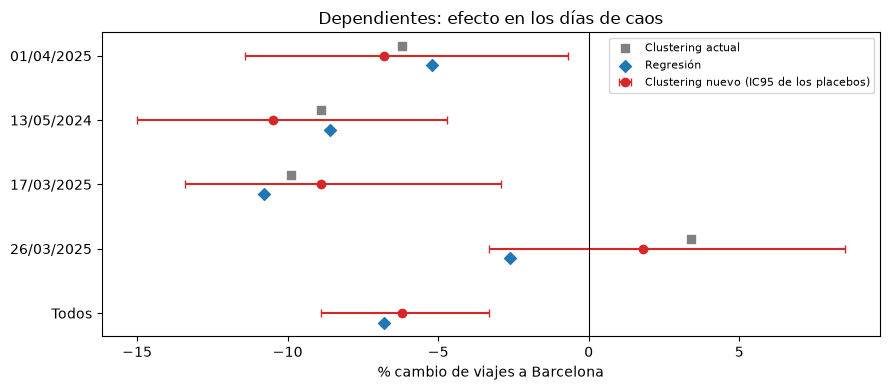

In [18]:
dd = final.loc["Dependientes"]
lo_hi = dd.IC95.str.strip("[]").str.split(",", expand=True).astype(float)
y = np.arange(len(dd))[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(dd["efecto_%"], y, xerr=[dd["efecto_%"] - lo_hi[0], lo_hi[1] - dd["efecto_%"]],
            fmt="o", color="C3", capsize=3, label="Clustering nuevo (IC95 de los placebos)")
ax.scatter(dd["actual_%"], y + .15, marker="s", color="0.5", label="Clustering actual")
ax.scatter(dd["regresión_%"], y - .15, marker="D", color="C0", label="Regresión")
ax.axvline(0, color="black", lw=.8); ax.set_yticks(y); ax.set_yticklabels(dd.index)
ax.set_xlabel("% cambio de viajes a Barcelona"); ax.set_title("Dependientes: efecto en los días de caos")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()